# Adversarial Search: Solving Tic-Tac-Toe with Heuristic Alpha-Beta Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. __Heuristic Alpha-Beta Tree Search:__ Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Heuristic Alpha-Beta Tree Search

The algorithms search the game tree and we could return a conditional plan (or partial plan if cut offs are used), but the implementation here only identifies and returns the optimal next move.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Heuristic Alpha-Beta Tree Search

See AIMA page 156ff. 


## Heuristic Evaluation Function

`eval_fun(state, player)` trả về `(điểm, terminal)`: trạng thái kết thúc dùng utility thật (thắng `1`, hòa `0`, thua `-1`); trạng thái chưa kết thúc cộng `0.4` cho mỗi hàng/cột/đường chéo có hai quân của `player` và một ô trống, đồng thời trừ `0.4` cho cơ hội tương tự của đối thủ. Heuristic có thể nằm trong `[-1.2, 1.2]` và vì thế vượt quá utility kết thúc `[-1, 1]`; ví dụ X ở ô 0, 2, 4 và O ở ô 3, 5 cho điểm `1.2`.

In [3]:
import numpy as np

def eval_fun(state, player = 'x'):
    """heuristic for utility of state. Returns score for a node:
    1. For terminal states it returns the utility. 
    2. For non-terminal states, it calculates a weighted linear function using features of the state. 
    The features we look at are 2 in a row/col/diagonal where the 3rd square is empty. We assume that
    the more of these positions we have, the higher the chance of winning.
    The heuristic can exceed the terminal utility range [-1,1]: up to three open two-in-a-row lines
    can contribute, so non-terminal scores can range from -1.2 to 1.2.
    
    Function Returns: heuristic value, terminal?"""
    
    # terminal state?
    u = utility(state, player)
    if u is not None: return u, True
      
    score = 0
    board = np.array(state).reshape((3,3))
    diagonals = np.array([[board[i][i] for i in range(len(board))], 
                          [board[i][len(board)-i-1] for i in range(len(board))]])
    
    for a_board in [board, np.transpose(board), diagonals]:
        for row in a_board:
            if sum(row == player) == 2 and any(row ==' '): score += .4
            if sum(row == other(player)) == 2 and any(row ==' '): score -= .4
    
    return score, False

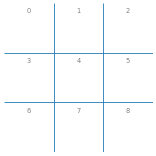

eval for x: (0, False)
eval for o: (0, False)


In [4]:
board = empty_board()
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

**Nhận xét:** Bàn rỗng chưa có đường mở hai quân cho bên nào, nên điểm của cả X và O đều là `0`.

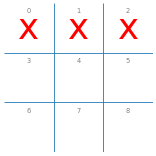

eval for x: (1, True)
eval for o: (-1, True)


In [5]:
board = empty_board()
board[0] = 'x'
board[1] = 'x'
board[2] = 'x'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

**Nhận xét:** X đã thắng nên trạng thái là kết thúc; `eval_fun` trả utility thật: `1` khi đánh giá cho X và `-1` cho O.

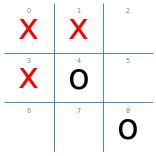

eval for x: (0.8, False)
eval for o: (-0.8, False)


In [6]:
board = empty_board()
board[0] = 'x'
board[1] = 'x'
board[3] = 'x'
board[4] = 'o'
board[8] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

**Nhận xét:** X có hai đường mở hai quân, mỗi đường đóng góp `0.4`; vì vậy điểm là `0.8` cho X và `-0.8` cho O.

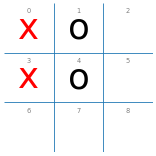

eval for x: (0.0, False)
eval for o: (0.0, False)


In [7]:
board = empty_board()
board[0] = 'x'
board[1] = 'o'
board[3] = 'x'
board[4] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

**Nhận xét:** Mỗi bên có một đường mở hai quân; hai đóng góp `+0.4` và `-0.4` triệt tiêu nhau nên điểm của cả X lẫn O là `0`.

## Tìm kiếm có giới hạn độ sâu (cutoff)

Ta thêm cutoff vào thuật toán DFS đệ quy của Minimax với cắt tỉa Alpha-Beta (tham khảo AIMA, trang 156 trở đi). Ở các nút biên, thuật toán dùng hàm heuristic để ước lượng giá trị rồi lan truyền giá trị bằng Minimax và Alpha-Beta nhằm chọn nước đi tiếp theo.

Độ sâu bắt đầu từ 0 tại bàn cờ hiện tại. Với `cutoff = 2` hoặc `4`, tìm kiếm dừng sau số ply tương ứng và đánh giá các nút biên; `cutoff = None` tiếp tục đến trạng thái kết thúc. `heuristic2_player` và `heuristic4_player` dùng các cutoff tương ứng, còn `alpha_beta_player` tìm đến trạng thái kết thúc.

In [8]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, cutoff = None, player = 'x'):
    """start the search. cutoff = None is minimax search with alpha-beta pruning."""
    global DEBUG, COUNT
    COUNT = 0

    value, move = max_value_ab(board, player, -math.inf, +math.inf, 0, cutoff)
    
    if DEBUG >= 1: print(f"Number of nodes searched (cutoff = {cutoff}): {COUNT}") 
    
    return {"move": move, "value": value}

def max_value_ab(state, player, alpha, beta, depth, cutoff):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta, depth + 1, cutoff)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta, depth, cutoff):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta, depth + 1, cutoff)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: return v, move
    
    return v, move

## Some Tests

### x is about to win (play 8)

Board:


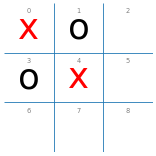


Number of nodes searched (cutoff = 2): 13


{'move': 8, 'value': 1}

CPU times: total: 0 ns
Wall time: 3.36 ms

Number of nodes searched (cutoff = 4): 47


{'move': 2, 'value': 1}

CPU times: total: 15.6 ms
Wall time: 3.35 ms

Number of nodes searched (cutoff = None): 61


{'move': 2, 'value': 1}

CPU times: total: 0 ns
Wall time: 7.63 ms


In [9]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))

print()
%time display(alpha_beta_search(board, 4))

print()
%time display(alpha_beta_search(board))

### o is about to win

Board:


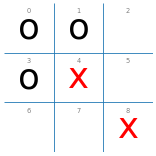


Number of nodes searched (cutoff = 2): 11


{'move': 2, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 3.25 ms

Number of nodes searched (cutoff = 4): 15


{'move': 2, 'value': -1}

CPU times: total: 0 ns
Wall time: 7.42 ms

Number of nodes searched (cutoff = None): 15


{'move': 2, 'value': -1}

CPU times: total: 0 ns
Wall time: 6.94 ms


In [10]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

### x can draw if it chooses 7

Board:


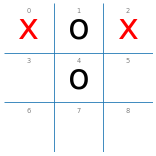


Number of nodes searched (cutoff = 2): 21


{'move': 7, 'value': -0.4}

CPU times: total: 0 ns
Wall time: 10 ms

Number of nodes searched (cutoff = 4): 81


{'move': 7, 'value': 0}

CPU times: total: 15.6 ms
Wall time: 7.42 ms

Number of nodes searched (cutoff = None): 101


{'move': 7, 'value': 0}

CPU times: total: 0 ns
Wall time: 7.68 ms


In [11]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

### Empty board: Only a draw an be guaranteed

Board:


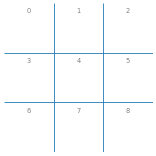


Number of nodes searched (cutoff = 2): 26


{'move': 0, 'value': 0}

CPU times: total: 15.6 ms
Wall time: 4.84 ms

Number of nodes searched (cutoff = 4): 541


{'move': 4, 'value': 0.0}

CPU times: total: 46.9 ms
Wall time: 42.1 ms

Number of nodes searched (cutoff = None): 18297


{'move': 0, 'value': 0}

CPU times: total: 1.31 s
Wall time: 1.38 s


In [12]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

### A bad situation

Board:


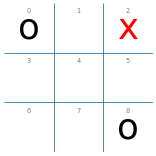


Number of nodes searched (cutoff = 2): 29


{'move': 4, 'value': -0.8}

CPU times: total: 31.2 ms
Wall time: 10.5 ms

Number of nodes searched (cutoff = 4): 148


{'move': 1, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 22.4 ms

Number of nodes searched (cutoff = None): 238


{'move': 1, 'value': -1}

CPU times: total: 62.5 ms
Wall time: 29.7 ms


In [13]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

### Bảng kết quả tìm kiếm

Chỉ số nước đi là vị trí ô trên bàn (0–8). Thời gian là Wall time (ms) của lần chạy mới nhất; số đo có thể thay đổi theo máy. Trung bình tính trên bốn bàn chính, không tính bàn “O sắp thắng”.

| Bàn kiểm thử | Phương pháp | Nước đi | Giá trị | Số nút | Wall time (ms) | Nhận xét |
| --- | --- | ---: | ---: | ---: | ---: | --- |
| X có thể thắng ngay | Heuristic Alpha-Beta cutoff = 2 | 8 | 1 | 13 | 3.36 | Cutoff 2 chỉ nhìn trước 2 ply nên chọn ô 8. |
| X có thể thắng ngay | Heuristic Alpha-Beta cutoff = 4 | 2 | 1 | 47 | 3.35 | Ô 2 cũng bảo đảm thắng (giá trị 1); Minimax không ưu tiên thắng sớm và giữ nước thắng đầu tiên tìm được. |
| X có thể thắng ngay | Alpha-Beta đầy đủ | 2 | 1 | 61 | 7.63 | Ô 2 vẫn bảo đảm thắng; tìm đầy đủ cũng không phân biệt thắng sớm hay muộn. |
| O sắp thắng | Heuristic Alpha-Beta cutoff = 2 | 2 | -1 | 11 | 3.25 | Không thể ngăn O thắng. |
| O sắp thắng | Heuristic Alpha-Beta cutoff = 4 | 2 | -1 | 15 | 7.42 | Nhìn sâu hơn nhưng vẫn không thể tránh thua. |
| O sắp thắng | Alpha-Beta đầy đủ | 2 | -1 | 15 | 6.94 | Xác nhận không thể tránh thua. |
| X có thể hòa nếu đi 7 | Heuristic Alpha-Beta cutoff = 2 | 7 | -0.4 | 21 | 10 | Heuristic đánh giá thấp hơn kết quả thật vì chưa nhìn đến cuối ván. |
| X có thể hòa nếu đi 7 | Heuristic Alpha-Beta cutoff = 4 | 7 | 0 | 81 | 7.42 | Phát hiện được kết quả hòa. |
| X có thể hòa nếu đi 7 | Alpha-Beta đầy đủ | 7 | 0 | 101 | 7.68 | Xác nhận hòa. |
| Bàn rỗng | Heuristic Alpha-Beta cutoff = 2 | 0 | 0 | 26 | 4.84 | Chọn góc; vẫn có thể bảo đảm hòa. |
| Bàn rỗng | Heuristic Alpha-Beta cutoff = 4 | 4 | 0 | 541 | 42.1 | Chọn trung tâm; kết quả vẫn là hòa. |
| Bàn rỗng | Alpha-Beta đầy đủ | 0 | 0 | 18,297 | 1,380 | Tìm hết cây; cũng chọn một nước hòa tối ưu. |
| Tình huống bất lợi | Heuristic Alpha-Beta cutoff = 2 | 4 | -0.8 | 29 | 10.5 | Đánh giá chưa thấy chắc chắn rằng sẽ thua. |
| Tình huống bất lợi | Heuristic Alpha-Beta cutoff = 4 | 1 | -1 | 148 | 22.4 | Phát hiện không tránh được thua. |
| Tình huống bất lợi | Alpha-Beta đầy đủ | 1 | -1 | 238 | 29.7 | Xác nhận kết quả thua tối ưu. |
| **Trung bình 4 bàn chính** | **Heuristic Alpha-Beta cutoff = 2** | — | — | **22.25** | **7.175** | Trung bình không gồm bàn “O sắp thắng”. |
| **Trung bình 4 bàn chính** | **Heuristic Alpha-Beta cutoff = 4** | — | — | **204.25** | **18.8175** | Chi phí cao hơn cutoff 2 nhưng dự đoán ổn định hơn. |
| **Trung bình 4 bàn chính** | **Alpha-Beta đầy đủ** | — | — | **4,674.25** | **356.2525** | Tìm chính xác đến trạng thái kết thúc, chi phí cao nhất. |

**Nhận xét:** Tăng cutoff làm số nút và thời gian tăng mạnh, nhất là bàn rỗng: Alpha-Beta đầy đủ duyệt `18,297` nút, trong khi cutoff 4 chỉ duyệt `541`. Cutoff nông có thể đánh giá sai vì chưa nhìn đến cuối ván: bàn chắc hòa bị chấm `-0.4`, còn thế thua bị chấm `-0.8`. Ở các bàn chính này, cutoff 4 cho kết quả gần như tìm đầy đủ nhưng ít nút hơn; cutoff 2 vẫn có thể chọn nước khác hoặc đánh giá sai kết quả.

Thời gian thực thi có thể dao động giữa các lần chạy và tùy máy.


## Experiments



### Minimax with Alpha-Beta Pruning vs. Random

In [14]:
def heuristic2_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 2, player = player)["move"]

def heuristic4_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 4, player = player)["move"]

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = None, player = player)["move"]

DEBUG = 1
print("heuristic2 vs. random:")
display(play(heuristic2_player, random_player, N = 3))

heuristic2 vs. random:
Number of nodes searched (cutoff = 2): 26


Number of nodes searched (cutoff = 2): 30
Number of nodes searched (cutoff = 2): 10
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 33
Number of nodes searched (cutoff = 2): 16
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 30
Number of nodes searched (cutoff = 2): 10


{'x': 3, 'o': 0, 'd': 0}

In [15]:
DEBUG = 0
print("heuristic2 vs. random:")
%time display(play(heuristic2_player, random_player))

print("heuristic4 vs. random:")
%time display(play(heuristic4_player, random_player))

print()
print("random vs. heuristic2")
%time display(play(random_player, heuristic2_player))

print("random vs. heuristic4")
%time display(play(random_player, heuristic4_player))

heuristic2 vs. random:


{'x': 95, 'o': 0, 'd': 5}

CPU times: total: 656 ms
Wall time: 684 ms
heuristic4 vs. random:


{'x': 98, 'o': 0, 'd': 2}

CPU times: total: 6.89 s
Wall time: 7.12 s

random vs. heuristic2


{'x': 3, 'o': 74, 'd': 23}

CPU times: total: 578 ms
Wall time: 593 ms
random vs. heuristic4


{'x': 0, 'o': 82, 'd': 18}

CPU times: total: 4.25 s
Wall time: 4.35 s


**Nhận xét:** Trong lần chạy này, heuristic2 thắng `95/100` khi đi trước (5 hòa, 0 thua) và thắng `74/100` khi đi sau (23 hòa, 3 thua). Heuristic4 thắng `98/100` khi đi trước (2 hòa, 0 thua) và `82/100` khi đi sau (18 hòa, 0 thua). Heuristic4 không thua ván nào trong 200 ván, trong khi heuristic2 thua 3 ván khi đi sau; kết quả này ủng hộ heuristic4, dù thời gian tìm kiếm lâu hơn đáng kể. Random không cố định seed nên kết quả có thể thay đổi giữa các lần chạy.

### Heuristic vs. Minimax with Alpha-Beta Pruning

In [16]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. alpha_beta")
%time display(play(heuristic2_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic2")
%time display(play(alpha_beta_player, heuristic2_player, N = 1))

print()
print("heuristic4 vs alpha_beta")
%time display(play(heuristic4_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic4")
%time display(play(alpha_beta_player, heuristic4_player, N = 1))

heuristic2 vs. alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 141 ms
Wall time: 128 ms

alpha_beta vs. heuristic2


{'x': 1, 'o': 0, 'd': 0}

CPU times: total: 1.05 s
Wall time: 1.08 s

heuristic4 vs alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 250 ms
Wall time: 243 ms

alpha_beta vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 1.05 s
Wall time: 1.1 s


**Nhận xét:** Heuristic2 hòa khi đi trước nhưng thua khi gặp Alpha-Beta đầy đủ đi trước; heuristic4 hòa ở cả hai lượt trong lần thử này. Độ sâu 4 vì vậy thể hiện chất lượng quyết định gần với tìm đầy đủ hơn ở các bàn này.

### Heuristic vs. Heuristic

In [17]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. heuristic4")
%time display(play(heuristic2_player, heuristic4_player, N = 1))

print()
print("heuristic4 vs. heuristic2")
%time display(play(heuristic4_player, heuristic2_player, N = 1))

heuristic2 vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 31.2 ms
Wall time: 35.6 ms

heuristic4 vs. heuristic2


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 62.5 ms
Wall time: 64.5 ms


**Nhận xét:** Hai cấu hình hòa khi đổi lượt đi trong lần thử này. Kết quả một ván không đủ để kết luận heuristic2 và heuristic4 có cùng chất lượng; các bàn kiểm thử và nhiều ván đấu cho thấy heuristic4 ước lượng sâu hơn, nhưng tốn nhiều thời gian hơn.

__Idea:__ Start experiments with different boards that already have a few x's and o's randomly placed on them.